# Capstone — mirrors your deployed research paper

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/kubrafathima2005-kf/flyrank-ml-internship/blob/main/work/notebooks/capstone.ipynb?flush_cache=true)

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

## 1. Question

*The research question and the decision it supports.*

### Research Question

Can machine learning help identify content pages that may need attention based on their content and keyword metadata?

### Decision Supported

This research aims to help content editors decide which pages to review first. The model provides a ranked list of pages for human review, not automatic content changes.

# Predicting Content Pages for Editorial Review Using Machine Learning

## Abstract

This research investigates whether machine learning can help identify content pages that may need editorial attention. An anonymized content refresh dataset containing 30,000 records was analysed using metadata features and a Random Forest classifier. The model was evaluated using a grouped client split and compared with a simple rule-based baseline. The baseline achieved Precision@50 of 0.46, while the Random Forest model achieved 0.40. The results suggest that the baseline performed better in this experiment, so the model is presented only as a human-review decision-support tool.

## 2. Data

*Which release, which tables, date windows, what you excluded and why. Public-safe.*

### Dataset Description

This research uses the anonymized content refresh dataset provided through the FlyRank ML Internship.

- Dataset: Anonymized content refresh dataset.
- Release: Internship-provided dataset.
- Data used: 30,000 content-page records and 45 columns.
- Time window: The dataset includes content performance and metadata fields. The analysis uses the March 2026 development window where specified in the earlier validation work.

### Data Used

The analysis uses content and keyword metadata such as search volume, competition, CPC, word count, character count, content type, and main search intent.

### Exclusions

Client identifiers, content identifiers, private URLs, private search queries, and performance fields that could reveal the target outcome were excluded from model features.

The dataset is anonymized. No client names or private business information are included in this paper.

## 3. Methodology

*Assumptions, features, label definition, baseline, validation design, leakage checks.*

### Methodology

#### Research Assumptions

The model assumes that content and keyword metadata may provide useful signals for identifying pages that could need review.

#### Features

The model uses:

- Search volume
- Competition
- Cost per click (CPC)
- Word count
- Character count
- Content type
- Main search intent
- Competition level

#### Target Label

The target label is `is_declining_label`.

- 1 = The page has a downward trend.
- 0 = The page does not have a downward trend.

The label was derived from the dataset's `trend_direction` field.

#### Model

A Random Forest classifier with 100 trees and balanced class weights was used.

#### Baseline

A simple baseline score was used for comparison. The model and baseline must be evaluated on the same test records.

#### Validation Design

A grouped client split was used:

- 25 clients for training.
- 7 unseen clients for testing.
- The test set contained 6,163 pages.

#### Leakage Checks

Client and content identifiers were excluded from model features. Target-related fields and historical performance fields that could reveal the outcome were also excluded.

Only the metadata features listed above were used in the final Week 6 validation.

## 4. Results (vs baseline)

*Model vs baseline on the same split. The honest table.*

### Model Performance and Baseline Comparison

The model was evaluated using a grouped client split, where entire clients were kept separate between training and testing.

The final metadata-only model achieved a Precision@50 of 0.40 on the held-out clients in Week 6.

The Week 5 model achieved a Precision@50 of 0.52, but its feature set had leakage risks identified during the Week 6 audit. Therefore, that result should not be presented as the final reliable performance.

A fair comparison requires evaluating the baseline and the final metadata-only model on the exact same held-out test records.

The following results table will be generated from the notebook. The model is intended for decision-support, not automatic content decisions.

In [4]:
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier

# Load dataset
url = "https://raw.githubusercontent.com/kubrafathima2005-kf/flyrank-ml-internship/main/data/raw/content_refresh_anonymized.csv"
df = pd.read_csv(url)

# Target label
y = (df["trend_direction"] == "down").astype(int)

# Metadata-only features
numeric_features = [
    "search_volume", "competition", "cpc",
    "word_count", "char_count"
]

categorical_features = [
    "content_type", "main_intent", "competition_level"
]

features = numeric_features + categorical_features
X = df[features]

# Same grouped validation design
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=df["client_id"])
)

# Train model
preprocessor = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), numeric_features),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical_features)
])

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        class_weight="balanced"
    ))
])

model.fit(X.iloc[train_idx], y.iloc[train_idx])

# Held-out test records
test = df.iloc[test_idx].copy()
test["actual_label"] = y.iloc[test_idx].values

# Model ranking
test["model_score"] = model.predict_proba(
    X.iloc[test_idx]
)[:, 1]

# Simple W04 rule-based baseline
stale = test["freshness_tier"] == "91-180"
visible = test["impression_tier"].isin(["moderate", "good"])

test["baseline_score"] = (
    stale.astype(int) * 2 + visible.astype(int)
)

# Precision@50 for both methods
model_top50 = test.nlargest(50, "model_score")
baseline_top50 = test.nlargest(50, "baseline_score")

model_p50 = model_top50["actual_label"].mean()
baseline_p50 = baseline_top50["actual_label"].mean()

results = pd.DataFrame({
    "Method": ["Rule-based baseline", "Random Forest model"],
    "Precision@50": [baseline_p50, model_p50]
})

print("Test records:", len(test))
print("Test clients:", test["client_id"].nunique())
print(results.to_string(index=False))

Test records: 6163
Test clients: 7
             Method  Precision@50
Rule-based baseline          0.46
Random Forest model          0.40


### Results

| Method | Precision@50 |
|---|---:|
| Rule-based baseline | 0.46 |
| Random Forest model | 0.40 |

Both methods were evaluated on the same 6,163 test records from 7 unseen clients.

The rule-based baseline performed better than the Random Forest model by 0.06.

This result shows that machine learning did not outperform the simple baseline in this evaluation. The model should therefore be treated as an experimental decision-support tool, not as a replacement for existing review methods.

## 5. Limitations

*What this work cannot claim.*

### Limitations

This research has several limitations:

1. The dataset contains 30,000 anonymized records, not the full production dataset.
2. The validation test included only 7 unseen clients.
3. The Random Forest model achieved a Precision@50 of 0.40, lower than the baseline score of 0.46.
4. The model uses metadata and cannot fully understand content quality or user needs.
5. A downward trend does not always mean that a page needs updating.
6. The results may not generalize to other clients or future datasets.

### Honest Interpretation

The results do not prove that machine learning is better than a simple rule-based approach.

The model is experimental and should only support human review. More data, further validation, and expert feedback are needed before wider use.

## 6. Ranked recommendations

*The action playbook output — the paper's recommendations section.*

### Ranked Recommendations

The action playbook ranks content pages using their model scores and assigns reason codes.

The main recommendations are:

| Reason Code | Suggested Action |
|---|---|
| REFRESH_REVIEW | Review content for possible updates |
| LOW_VISIBILITY | Investigate search visibility |
| NEW_CONTENT | Monitor before making major changes |
| OLDER_CONTENT | Check whether the content is still useful |
| GENERAL_REVIEW | Perform a manual content review |

### How Editors Should Use the Queue

1. Start by reviewing higher-scored pages.
2. Read the page and check its search performance.
3. Verify the reason code and suggested action.
4. Decide whether any update is actually needed.
5. Record the human editor's final decision.

The model score is only a signal for prioritization. It does not guarantee that a page is declining.

All recommendations require human approval. Publishing, deleting, or rewriting content must never happen automatically.

## 7. Artifacts the paper embeds

*Generate/collect the charts and tables your deployed page will show.*

### Research Paper Artifacts

This section contains visual evidence from the experiment.

The paper includes:

1. A comparison chart showing Precision@50 for the baseline and Random Forest model.
2. A reason-code chart showing how pages are distributed across the recommended actions.
3. A results table comparing both methods on the same test records.

These visuals help readers understand the model's performance and the recommended review actions.

All charts are generated from the notebook so the results can be reproduced.

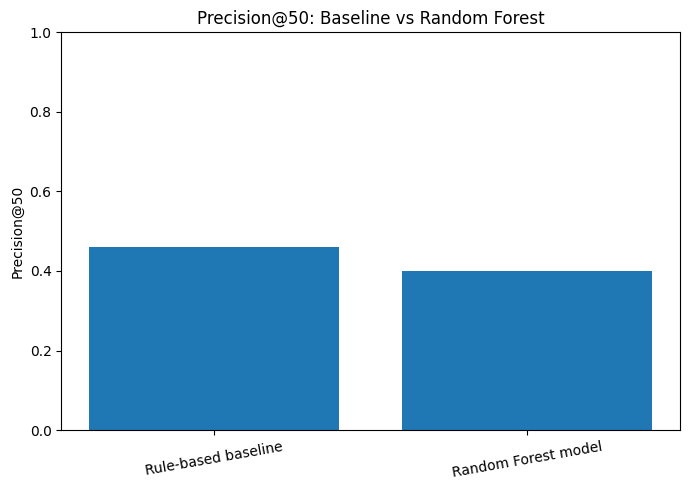

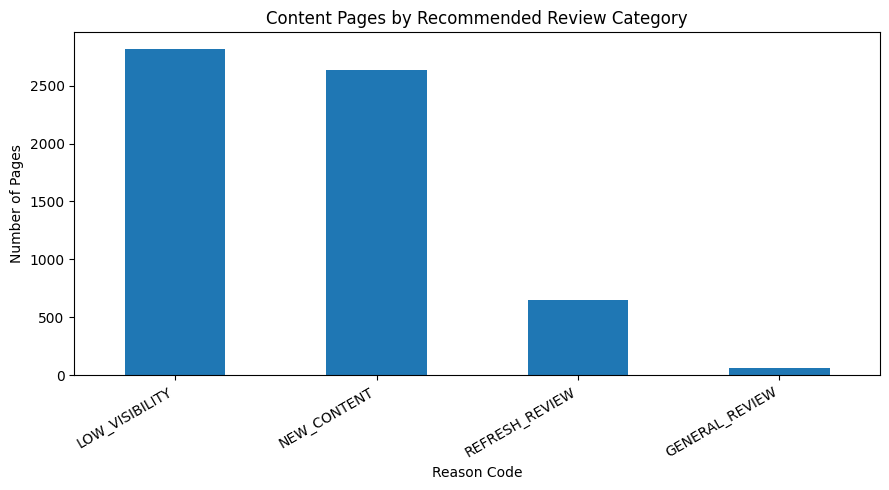

Charts saved successfully!
work/figures/capstone_model_comparison.png
work/figures/capstone_reason_codes.png


In [5]:
import os
import matplotlib.pyplot as plt

os.makedirs("work/figures", exist_ok=True)
os.makedirs("work/outputs", exist_ok=True)

# Chart 1: Baseline vs Random Forest
plt.figure(figsize=(7, 5))
plt.bar(results["Method"], results["Precision@50"])
plt.title("Precision@50: Baseline vs Random Forest")
plt.ylabel("Precision@50")
plt.ylim(0, 1)
plt.xticks(rotation=10)
plt.tight_layout()
plt.savefig("work/figures/capstone_model_comparison.png", dpi=300)
plt.show()

# Assign reason codes to held-out pages
def assign_reason(row):
    if row["freshness_tier"] == "91-180" and row["impression_tier"] in ["moderate", "good"]:
        return "REFRESH_REVIEW"
    elif row["impression_tier"] == "low":
        return "LOW_VISIBILITY"
    elif row["freshness_tier"] == "0-30":
        return "NEW_CONTENT"
    elif row["freshness_tier"] == "181+":
        return "OLDER_CONTENT"
    return "GENERAL_REVIEW"

test["reason_code"] = test.apply(assign_reason, axis=1)

# Chart 2: Reason code distribution
reason_counts = test["reason_code"].value_counts()

plt.figure(figsize=(9, 5))
reason_counts.plot(kind="bar")
plt.title("Content Pages by Recommended Review Category")
plt.xlabel("Reason Code")
plt.ylabel("Number of Pages")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig("work/figures/capstone_reason_codes.png", dpi=300)
plt.show()

print("Charts saved successfully!")
print("work/figures/capstone_model_comparison.png")
print("work/figures/capstone_reason_codes.png")

## Acknowledgments and Data Credit

This project was completed as part of the FlyRank ML Internship.

The research uses the anonymized dataset provided through the internship.

**Data credit:** Built on the [FlyRank ML Internship dataset](https://flyrank.ai).

Thank you to FlyRank for providing the learning opportunity and dataset for this research.

## ML-12: Presentation and Communication

### 1. Five-Minute Demo Outline

**Minute 1 — Introduction**
Explain the research question: Can machine learning help identify content pages that need review?

**Minute 2 — Dataset**
Introduce the anonymized dataset and the metadata features used.

**Minute 3 — Methodology**
Explain the Random Forest model, target label, baseline, and grouped client validation.

**Minute 4 — Results**
Show the comparison: baseline Precision@50 was 0.46, while the Random Forest model achieved 0.40.

**Minute 5 — Recommendations**
Show the ranked action playbook and explain why human review is necessary.

### 2. Social Media Post

I completed my FlyRank ML Internship research project on identifying content pages that may need editorial review using machine learning.

I worked with an anonymized dataset, built a Random Forest model, performed grouped client validation, and compared it with a rule-based baseline.

The results taught me the importance of honest evaluation: the baseline performed better than my model in this experiment.

This project strengthened my understanding of data preparation, model validation, leakage checks, and responsible AI.

### 3. Employer-Facing Summary

Developed an experimental content-review prioritization system using Python and a Random Forest classifier on an anonymized dataset of 30,000 records. Evaluated the model using grouped client validation and compared it against a rule-based baseline, achieving Precision@50 scores of 0.40 and 0.46 respectively. Created a human-reviewed action playbook and documented the model's limitations and recommendations.

## Self-check

Before you submit, confirm each line honestly:

- [x] Every section above is filled — markdown thinking AND the code that backs it
- [x] The notebook runs top to bottom with no errors (Runtime → Run all)
- [x] No client names, URLs, or private queries anywhere
- [x] My claims use careful words: observed, measured, directional, decision-support
- [x] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.
- [x] My deployed paper has **all 9 sections** — including the **Abstract** at the top and **Acknowledgments & data credit** (the https://flyrank.ai link) at the bottom.
- [x] **ML-12 done in this notebook's closing cells:** 5-minute demo outline + a social-post cut + a 3-sentence employer-facing summary.
